# Experimento 3. RoPE y coste computacional

## 1. Configuración
Prepararemos PyTorch, Pandas y Matplotlib. Usaremos FP32 en la prueba analítica y FP16 para medir rendimiento en CUDA (FP32 si solo tenemos CPU). Guardaremos las tablas en `resultados_exp3/` y las figuras en `figuras_exp3/`, sobrescribiendo los archivos al repetir la ejecución.

In [1]:
import time
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
import torch
from IPython.display import display

# Abriremos el notebook desde la raíz del proyecto o desde su propia carpeta.
raiz = Path.cwd()
if not (raiz / 'minigpt').is_dir():
    raiz = raiz.parent
sys.path.insert(0, str(raiz))

from minigpt.config import GPTConfig
from minigpt.model import GPTModel
from minigpt.rope import RoPECache, apply_rotary

torch.manual_seed(42)
dispositivo = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
precision = torch.float16 if dispositivo.type == 'cuda' else torch.float32
nombre_precision = 'FP16' if precision == torch.float16 else 'FP32'

carpeta_experimentos = raiz / 'experimentos_2_y_3'
resultados = carpeta_experimentos / 'resultados_exp3'
figuras = carpeta_experimentos / 'figuras_exp3'
resultados.mkdir(exist_ok=True)
figuras.mkdir(exist_ok=True)
plt.rcParams.update({'figure.figsize': (7, 4), 'font.size': 11, 'savefig.dpi': 300})

def sincronizar():
    if dispositivo.type == 'cuda':
        torch.cuda.synchronize(dispositivo)

print(f'Dispositivo: {dispositivo} | Precisión: {precision}')
if dispositivo.type == 'cuda':
    print(torch.cuda.get_device_name(dispositivo))
else:
    print('Mediremos tiempos en CPU; la VRAM no estará disponible.')
print(f'Guardaremos los resultados en: {resultados}')

Dispositivo: cuda | Precisión: torch.float16
NVIDIA GeForce RTX 5070 Laptop GPU
Guardaremos los resultados en: C:\Users\cavir.ROG-CARLOS\Desktop\PLN-Practica\Practica1_PLN1\experimentos_2_y_3\resultados_exp3


## 2. Carga de los modelos entrenados
Cargaremos los mejores checkpoints de la fase **DACSA definitiva**, después del entrenamiento en OPUS100, con sus configuraciones originales. Elegiremos la misma semilla para ambos. No sustituiremos estos archivos por checkpoints piloto ni por los antiguos modelos pequeños.

In [2]:
semilla_checkpoint = 42
rutas = {
    'Learned': carpeta_experimentos / 'pesos' / 'learned' / f'best_dacsa_seed{semilla_checkpoint}.pt',
    'RoPE': carpeta_experimentos / 'pesos' / 'rope' / f'best_dacsa_seed{semilla_checkpoint}.pt',
}
faltantes = [str(ruta) for ruta in rutas.values() if not ruta.is_file()]
if faltantes:
    raise FileNotFoundError(
        'Faltan los checkpoints DACSA definitivos: ' + ', '.join(faltantes)
        + '. Primero completaremos las dos fases del experimento 2. No usaremos pesos aleatorios ni piloto.')

modelos, configuraciones, vocabularios = {}, {}, {}
for nombre, ruta in rutas.items():
    checkpoint = torch.load(ruta, map_location='cpu', weights_only=True)
    if checkpoint.get('fase') != 'dacsa' or checkpoint.get('modo') != 'definitivo':
        raise ValueError(f'{ruta}: necesitamos un checkpoint de la fase DACSA definitiva.')
    configuracion = GPTConfig(**checkpoint['model_config'])
    esquema = 'learned' if nombre == 'Learned' else 'rope'
    if configuracion.positional != esquema:
        raise ValueError(f'{ruta}: la configuración no corresponde al modelo {nombre}.')
    modelo = GPTModel(configuracion)
    modelo.load_state_dict(checkpoint['model_state_dict'], strict=True)
    modelos[nombre] = modelo.eval()
    configuraciones[nombre] = configuracion
    vocabularios[nombre] = checkpoint['huella_vocabulario']
    del checkpoint

config_learned = vars(configuraciones['Learned'])
config_rope = vars(configuraciones['RoPE'])
if any(config_learned[campo] != config_rope[campo]
       for campo in config_learned if campo != 'positional'):
    raise ValueError('Los checkpoints deben tener la misma configuración salvo positional.')
if vocabularios['Learned'] != vocabularios['RoPE']:
    raise ValueError('Los modelos deben utilizar el mismo vocabulario de caracteres.')

tabla_configuracion = pd.DataFrame({nombre: vars(cfg) for nombre, cfg in configuraciones.items()})
display(tabla_configuracion)
tabla_configuracion.to_csv(resultados / 'configuracion.csv')
pd.Series({nombre: str(ruta) for nombre, ruta in rutas.items()}, name='checkpoint').to_csv(
    resultados / 'checkpoints.csv')

,Learned,RoPE
vocab_size,3374,3374
context_length,512,512
emb_dim,256,256
n_heads,4,4
n_layers,4,4
drop_rate,0.0,0.0
qkv_bias,True,True
positional,learned,rope
rope_theta,10000.0,10000.0


## 3. Validación analítica de RoPE
Ahora comprobaremos que, manteniendo Q y K fijos, desplazar sus dos posiciones no cambia el producto escalar si conservamos la separación:

$$ (R_m q)^\top (R_n k) = q^\top R_{n-m} k. $$

Usaremos los mismos 16 pares Q/K normalizados en distintas posiciones y compararemos con `(0, separación)`. Aplicaremos `RoPECache` y `apply_rotary` del proyecto en CPU y FP32, la precisión original de sus tablas trigonométricas.

,error_medio,error_maximo
separacion,,
0,8.880826e-09,4.470348e-08
1,7.557017e-08,1.206994e-06
4,5.922214e-08,4.954636e-07
16,6.981593e-08,6.258488e-07
64,7.672601e-08,5.662441e-07
128,8.988094e-08,8.791685e-07


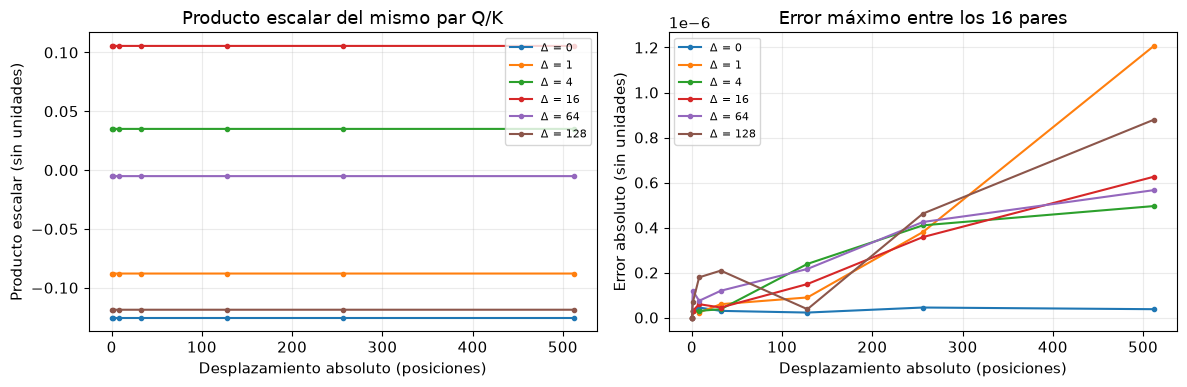

Error absoluto máximo: 1.2069940567016602e-06


In [3]:
cfg = configuraciones['RoPE']
generador = torch.Generator().manual_seed(42)
q = torch.randn(16, 1, 1, cfg.head_dim, generator=generador, dtype=torch.float32)
k = torch.randn(16, 1, 1, cfg.head_dim, generator=generador, dtype=torch.float32)
q = torch.nn.functional.normalize(q, dim=-1)
k = torch.nn.functional.normalize(k, dim=-1)
separaciones = [0, 1, 4, 16, 64, 128]
desplazamientos = [0, 1, 8, 32, 128, 256, 512]
cache = RoPECache(cfg.head_dim, max(desplazamientos) + max(separaciones) + 1, cfg.rope_theta)

filas_rope = []
with torch.inference_mode():
    for separacion in separaciones:
        coseno, seno = cache.get(1, offset=separacion)
        referencia = (q * apply_rotary(k, coseno, seno)).sum(dim=-1)
        for desplazamiento in desplazamientos:
            coseno, seno = cache.get(1, offset=desplazamiento)
            q_rotada = apply_rotary(q, coseno, seno)
            coseno, seno = cache.get(1, offset=desplazamiento + separacion)
            k_rotada = apply_rotary(k, coseno, seno)
            producto = (q_rotada * k_rotada).sum(dim=-1)
            error = (producto - referencia).abs()
            filas_rope.append({
                'separacion': separacion, 'desplazamiento': desplazamiento,
                'producto_par_0': producto[0].item(),
                'error_medio': error.mean().item(), 'error_maximo': error.max().item(),
            })

tabla_rope = pd.DataFrame(filas_rope)
tabla_rope.to_csv(resultados / 'validacion_rope.csv', index=False)
display(tabla_rope.groupby('separacion').agg(
    error_medio=('error_medio', 'mean'), error_maximo=('error_maximo', 'max')) )

figura, ejes = plt.subplots(1, 2, figsize=(12, 4))
for separacion, grupo in tabla_rope.groupby('separacion'):
    ejes[0].plot(grupo['desplazamiento'], grupo['producto_par_0'], marker='o',
                 markersize=3, label=f'Δ = {separacion}')
    ejes[1].plot(grupo['desplazamiento'], grupo['error_maximo'], marker='o',
                 markersize=3, label=f'Δ = {separacion}')
ejes[0].set(title='Producto escalar del mismo par Q/K',
            xlabel='Desplazamiento absoluto (posiciones)', ylabel='Producto escalar (sin unidades)')
ejes[1].set(title='Error máximo entre los 16 pares',
            xlabel='Desplazamiento absoluto (posiciones)', ylabel='Error absoluto (sin unidades)')
for eje in ejes:
    eje.grid(alpha=0.25)
    eje.legend(fontsize=8)
figura.tight_layout()
figura.savefig(figuras / 'invariancia_relativa.png')
plt.show()
print('Error absoluto máximo:', tabla_rope['error_maximo'].max())

Interpretaremos estos errores como una comprobación con Q y K fijos, no como una prueba de invariancia del modelo completo al cambiar el contexto.

## 4. Comparación computacional
Primero contaremos los parámetros totales y los posicionales de cada modelo.

In [4]:
tabla_parametros = pd.DataFrame([
    {'modelo': nombre, 'parametros_totales': sum(p.numel() for p in modelo.parameters()),
     'parametros_posicionales': modelo.positional_parameters}
    for nombre, modelo in modelos.items()
])
display(tabla_parametros)
tabla_parametros.to_csv(resultados / 'parametros.csv', index=False)

,modelo,parametros_totales,parametros_posicionales
0,Learned,5018112,131072
1,RoPE,4887040,0


Ahora mediremos el forward completo, incluidos los logits, en evaluación y sin gradientes. Usaremos lote 1, las mismas entradas y FP16 en CUDA (FP32 en CPU). Los IDs sintéticos servirán solo como carga de trabajo: no mediremos calidad lingüística ni generación token a token.

Probaremos cuatro longitudes calculadas a partir del contexto máximo de los checkpoints, sin superarlo. Inicializaremos primero las operaciones CUDA con ambos modelos para no atribuir al primero la memoria interna de cuBLAS. Para cada longitud haremos 5 forwards de calentamiento y 5 mediciones de 10 forwards, sincronizando CUDA. Dejaremos fuera del tiempo la carga y las transferencias; mantendremos solo un modelo en GPU.

Mediremos la memoria asignada por PyTorch: **modelo** sin entrada, **previa** justo antes del forward y **pico** durante su ejecución. Calcularemos **incremento = pico − previa**, sin incluir la entrada ni otros tensores ya asignados. Descontaremos la memoria ajena al experimento en las columnas de modelo, previa y pico. No será toda la VRAM de `nvidia-smi`; en CPU no tendremos estos datos.

In [5]:
lote = 1
calentamiento = 5
repeticiones = 5
iteraciones = 10
contexto_maximo = min(configuracion.context_length for configuracion in configuraciones.values())
longitudes = sorted({max(1, contexto_maximo // factor) for factor in [8, 4, 2, 1]})
print(f'Contexto máximo: {contexto_maximo} | Longitudes: {longitudes}')
generador = torch.Generator().manual_seed(43)
entradas_cpu = torch.randint(cfg.vocab_size, (lote, max(longitudes)), generator=generador)
mediciones = []

# Inicializaremos las bibliotecas CUDA antes de medir la memoria de cada modelo.
if dispositivo.type == 'cuda':
    with torch.inference_mode():
        for modelo in modelos.values():
            modelo.to(device=dispositivo, dtype=precision)
            entrada = entradas_cpu.to(dispositivo)
            modelo(entrada)
            sincronizar()
            del entrada
            modelo.to('cpu')
    torch.cuda.empty_cache()

with torch.inference_mode():
    for nombre, modelo in modelos.items():
        sincronizar()
        memoria_ajena = (torch.cuda.memory_allocated(dispositivo)
                         if dispositivo.type == 'cuda' else 0)
        modelo.to(device=dispositivo, dtype=precision)
        sincronizar()
        base_mib = ((torch.cuda.memory_allocated(dispositivo) - memoria_ajena) / 2**20
                    if dispositivo.type == 'cuda' else float('nan'))
        for longitud in longitudes:
            entrada = entradas_cpu[:, :longitud].contiguous().to(dispositivo)
            for _ in range(calentamiento):
                salida = modelo(entrada)
                if _ == calentamiento - 1 and not torch.isfinite(salida).all().item():
                    raise ValueError('Salida no finita: revisaremos la precisión de ambos modelos.')
                del salida
            sincronizar()
            for repeticion in range(repeticiones):
                sincronizar()
                inicio = time.perf_counter()
                for _ in range(iteraciones):
                    modelo(entrada)
                sincronizar()
                segundos = time.perf_counter() - inicio

                previa_mib = pico_mib = incremento_mib = float('nan')
                if dispositivo.type == 'cuda':
                    sincronizar()
                    memoria_previa = torch.cuda.memory_allocated(dispositivo)
                    torch.cuda.reset_peak_memory_stats(dispositivo)
                    modelo(entrada)
                    sincronizar()
                    pico = torch.cuda.max_memory_allocated(dispositivo)
                    previa_mib = (memoria_previa - memoria_ajena) / 2**20
                    pico_mib = (pico - memoria_ajena) / 2**20
                    incremento_mib = (pico - memoria_previa) / 2**20
                mediciones.append({
                    'modelo': nombre, 'longitud': longitud, 'repeticion': repeticion + 1,
                    'tiempo_ms': segundos / iteraciones * 1000,
                    'tokens_s': lote * longitud * iteraciones / segundos,
                    'modelo_vram_mib': base_mib, 'previa_vram_mib': previa_mib,
                    'pico_vram_mib': pico_mib, 'incremento_vram_mib': incremento_mib,
                })
            del entrada
        modelo.to('cpu')
        if dispositivo.type == 'cuda':
            torch.cuda.empty_cache()
        print(f'{nombre}: mediciones terminadas.')

tabla_mediciones = pd.DataFrame(mediciones)
tabla_mediciones.to_csv(resultados / 'mediciones.csv', index=False)
resumen = tabla_mediciones.groupby(['modelo', 'longitud']).agg(
    tiempo_ms=('tiempo_ms', 'mean'), tiempo_std_ms=('tiempo_ms', 'std'),
    tokens_s=('tokens_s', 'mean'), tokens_std_s=('tokens_s', 'std'),
    modelo_vram_mib=('modelo_vram_mib', 'mean'), previa_vram_mib=('previa_vram_mib', 'mean'),
    pico_vram_mib=('pico_vram_mib', 'mean'), incremento_vram_mib=('incremento_vram_mib', 'mean'),
).reset_index()
display(resumen[['modelo', 'longitud', 'tiempo_ms', 'tiempo_std_ms', 'tokens_s', 'tokens_std_s']].round(3))
resumen.to_csv(resultados / 'resumen.csv', index=False)
pd.Series({'dispositivo': str(dispositivo), 'precision': str(precision), 'lote': lote,
           'calentamiento': calentamiento, 'repeticiones': repeticiones,
           'iteraciones': iteraciones}, name='valor').to_csv(resultados / 'condiciones.csv')

Contexto máximo: 512 | Longitudes: [64, 128, 256, 512]


Learned: mediciones terminadas.


RoPE: mediciones terminadas.


,modelo,longitud,tiempo_ms,tiempo_std_ms,tokens_s,tokens_std_s
0,Learned,64,2.340,0.043,27363.221,496.723
1,Learned,128,2.381,0.079,53808.630,1749.479
2,Learned,256,2.232,0.070,114797.062,3493.221
3,Learned,512,2.347,0.118,218615.025,10738.626
4,RoPE,64,2.945,0.114,21759.761,832.702
5,RoPE,128,3.163,0.803,42091.282,7972.103
6,RoPE,256,2.824,0.075,90693.710,2416.247
7,RoPE,512,2.920,0.130,175629.216,7517.970


Representaremos la velocidad media con su desviación estándar. Después veremos la memoria del modelo, la previa y el incremento del forward; la altura total de cada barra será el pico.

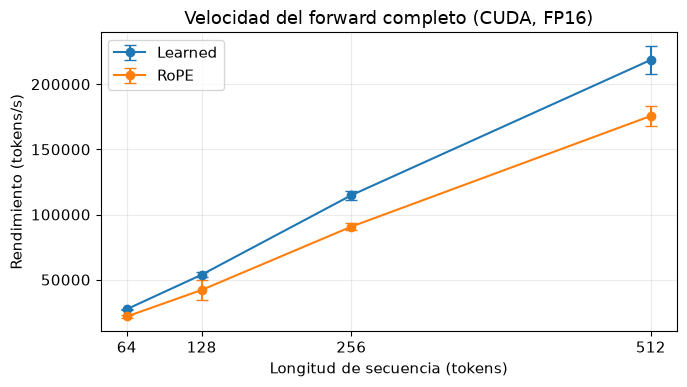

,modelo,longitud,modelo_vram_mib,previa_vram_mib,pico_vram_mib,incremento_vram_mib
0,Learned,64,11.57,11.57,12.17,0.59
1,Learned,128,11.57,11.57,12.76,1.19
2,Learned,256,11.57,11.57,13.95,2.38
3,Learned,512,11.57,11.58,19.08,7.50
4,RoPE,64,11.82,11.82,12.42,0.59
5,RoPE,128,11.82,11.82,13.01,1.19
6,RoPE,256,11.82,11.82,14.20,2.38
7,RoPE,512,11.82,11.83,19.33,7.50


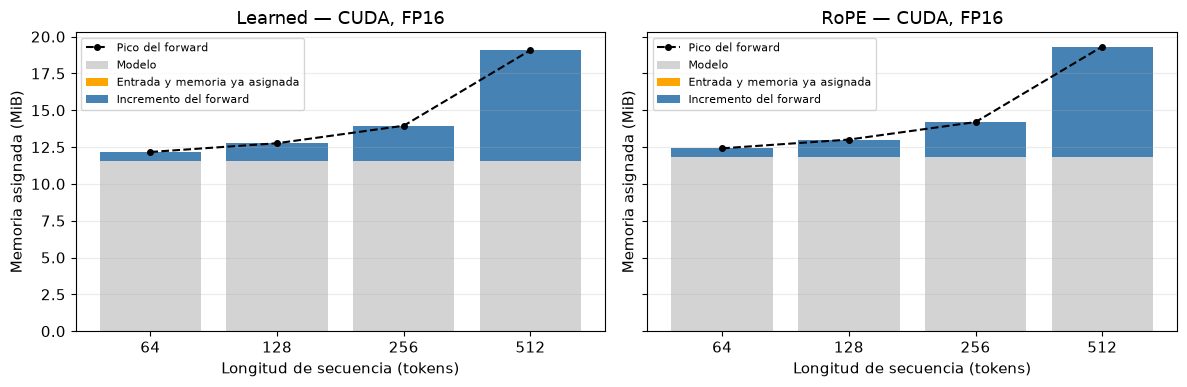

In [6]:
figura, eje = plt.subplots()
for nombre, grupo in resumen.groupby('modelo'):
    eje.errorbar(grupo['longitud'], grupo['tokens_s'], yerr=grupo['tokens_std_s'],
                 marker='o', capsize=4, label=nombre)
eje.set(title=f'Velocidad del forward completo ({dispositivo.type.upper()}, {nombre_precision})',
        xlabel='Longitud de secuencia (tokens)', ylabel='Rendimiento (tokens/s)')
eje.set_xticks(longitudes)
eje.grid(alpha=0.25)
eje.legend()
figura.tight_layout()
figura.savefig(figuras / 'velocidad.png')
plt.show()

if dispositivo.type == 'cuda':
    display(resumen[['modelo', 'longitud', 'modelo_vram_mib', 'previa_vram_mib', 'pico_vram_mib',
                     'incremento_vram_mib']].round(2))
    figura, ejes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
    for eje, (nombre, grupo) in zip(ejes, resumen.groupby('modelo')):
        posiciones = grupo['longitud'].astype(str)
        eje.bar(posiciones, grupo['modelo_vram_mib'], color='lightgray', label='Modelo')
        eje.bar(posiciones, grupo['previa_vram_mib'] - grupo['modelo_vram_mib'],
                bottom=grupo['modelo_vram_mib'], color='orange', label='Entrada y memoria ya asignada')
        eje.bar(posiciones, grupo['incremento_vram_mib'], bottom=grupo['previa_vram_mib'],
                color='steelblue', label='Incremento del forward')
        eje.plot(posiciones, grupo['pico_vram_mib'], 'ko--', markersize=4, label='Pico del forward')
        eje.set(title=f'{nombre} — CUDA, {nombre_precision}',
                xlabel='Longitud de secuencia (tokens)', ylabel='Memoria asignada (MiB)')
        eje.legend(fontsize=8)
        eje.grid(axis='y', alpha=0.25)
    figura.tight_layout()
    figura.savefig(figuras / 'memoria.png')
    plt.show()
else:
    print('VRAM no disponible: la medición se ha realizado en CPU.')